# clock/12 — systematic goal-head evaluation on the multi-predicate setup

**Question.** Run GoalScope on a fresh `check_conditions(n: int)` implementation and ask, at each
interesting token position: *given what the model is actually implementing there, is the GoalScope
read-out a faithful description of it?*

**Pipeline (one example):**
1. **Generate** the implementation — cut the prompt at `def check_conditions(n: int):\n`, greedy-decode
   the body `    a = …\n    b = …\n    c = …` (letters naming).
2. **Part (i) — oracle spans.** `label_generation` (cf. `01_data §3`) segments the generation into
   per-condition token spans + the condition description (`step_text`). This is the **truth**.
3. **GoalScope read-outs.** `apply_goalscope` → one verbalization per code token.
4. **Anchor positions.** Per assignment line: `VAR` (`a`/`b`/`c`), `=`, `indent` (line's leading
   whitespace, "−1"), `prev_end` (newline ending the previous line, "−2").
5. **Part (ii) — scoring** (truth = the implementation, not the read-out):
   - **soft** (reference = the *condition description*): graded oracle faithfulness `read-out ↔ step_text`
     — the analog of `09 §6`.
   - **hard** (reference = the *implementation span*): oracle YES/NO/MALFORMED `read-out ↔ gen_code`
     — the analog of `09 §7`, roles swapped.
6. **Scale-up preview.** A few examples → faithfulness aggregated **by anchor type**, previewing the
   grid the eventual script sweeps: `{heads, alpha, replace/additive, layer_range}`.

Everything below reuses existing code (`condition_data`, `multistep_label`, `goalscope`,
`oracle_llms`); nothing here is a new parallel implementation.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,3,7")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from rich.text import Text
from rich.markup import escape
from src.utils import logging_utils, env_utils
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

In [2]:
from src.models import ModelandTokenizer
# MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
# MODEL_NAME = "meta-llama/Llama-3.3-70B-Instruct"
MODEL_NAME = "allenai/Olmo-3.1-32B-Instruct"

mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER = mt.n_layer
N_HEADS = mt.model.config.num_attention_heads
print(f"n_layer={N_LAYER}  n_embd={mt.n_embd}  n_heads={N_HEADS}")

2026-08-05 17:08:50 src.models WARNING  allenai/Olmo-3.1-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-08-05 17:08:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/allenai/Olmo-3.1-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-05 17:08:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/allenai/Olmo-3.1-32B-Instruct/ac0587e4a7744a551c059d8cd17ba220bc940dae/config.json "HTTP/1.1 200 OK"


`rope_parameters`'s beta_fast field must be a float, got 32
`rope_parameters`'s beta_slow field must be a float, got 1


2026-08-05 17:08:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/allenai/Olmo-3.1-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-05 17:08:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/allenai/Olmo-3.1-32B-Instruct/ac0587e4a7744a551c059d8cd17ba220bc940dae/tokenizer_config.json "HTTP/1.1 200 OK"
2026-08-05 17:08:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/allenai/Olmo-3.1-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-05 17:08:50 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/allenai/Olmo-3.1-32B-Instruct/ac0587e4a7744a551c059d8cd17ba220bc940dae/tokenizer_config.json "HTTP/1.1 200 OK"
2026-08-05 17:08:50 httpx INFO     HTTP Request: GET https://huggingface.co/api/models/allenai/Olmo-3.1-32B-Instruct/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-08-05 17:0

`rope_parameters`'s beta_fast field must be a float, got 32
`rope_parameters`'s beta_slow field must be a float, got 1


Loading weights:   0%|          | 0/707 [00:00<?, ?it/s]

2026-08-05 17:09:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/allenai/Olmo-3.1-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-05 17:09:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/allenai/Olmo-3.1-32B-Instruct/ac0587e4a7744a551c059d8cd17ba220bc940dae/generation_config.json "HTTP/1.1 200 OK"
2026-08-05 17:09:15 src.models INFO     loaded model <allenai/Olmo-3.1-32B-Instruct> | size: 61480.565 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_embd=5120  n_heads=40


## 1. Head sets + GoalScope config

`goal_heads` = trained mask @0.9, 32B band 25–55 (as in `09.1`/`11`). `GOALSCOPE_CONFIG` holds the
knobs the grid-search script will sweep — here we fix one config and vary only the corpus.

In [3]:
from src.goals.head_loc_attn import HeadMask

# ── goal heads (trained mask @0.9, 32B band 25-55) — copied from 11 cell 4 ──
GOAL_THRESHOLD = 0.9
if MODEL_NAME == "Qwen/Qwen2.5-Coder-32B-Instruct":
    GOAL_BAND = (25, 56)
elif MODEL_NAME == "meta-llama/Llama-3.3-70B-Instruct":
    GOAL_BAND = (18, 45)
elif MODEL_NAME == "allenai/Olmo-3.1-32B-Instruct":
    GOAL_BAND = (10, 36)
else:
    GOAL_BAND = (0, mt.n_layer)
gck = torch.load(os.path.join(env_utils.DEFAULT_RESULTS_DIR,
                 f"localization/{MODEL_NAME.split('/')[-1]}/lam20/head_mask.pt"), map_location="cpu")
goal_layers = [int(x) for x in gck["layers"]]
gmask = gck["mask_values"].numpy().copy()
gmask[:GOAL_BAND[0]] = 0; gmask[GOAL_BAND[1]:] = 0
goal_heads = [(goal_layers[li], int(h)) for li, h in np.argwhere(gmask > GOAL_THRESHOLD)]
print(f"goal heads (@{GOAL_THRESHOLD}, band {GOAL_BAND[0]}-{GOAL_BAND[1]-1}): {len(goal_heads)}")

goal heads (@0.9, band 10-35): 130


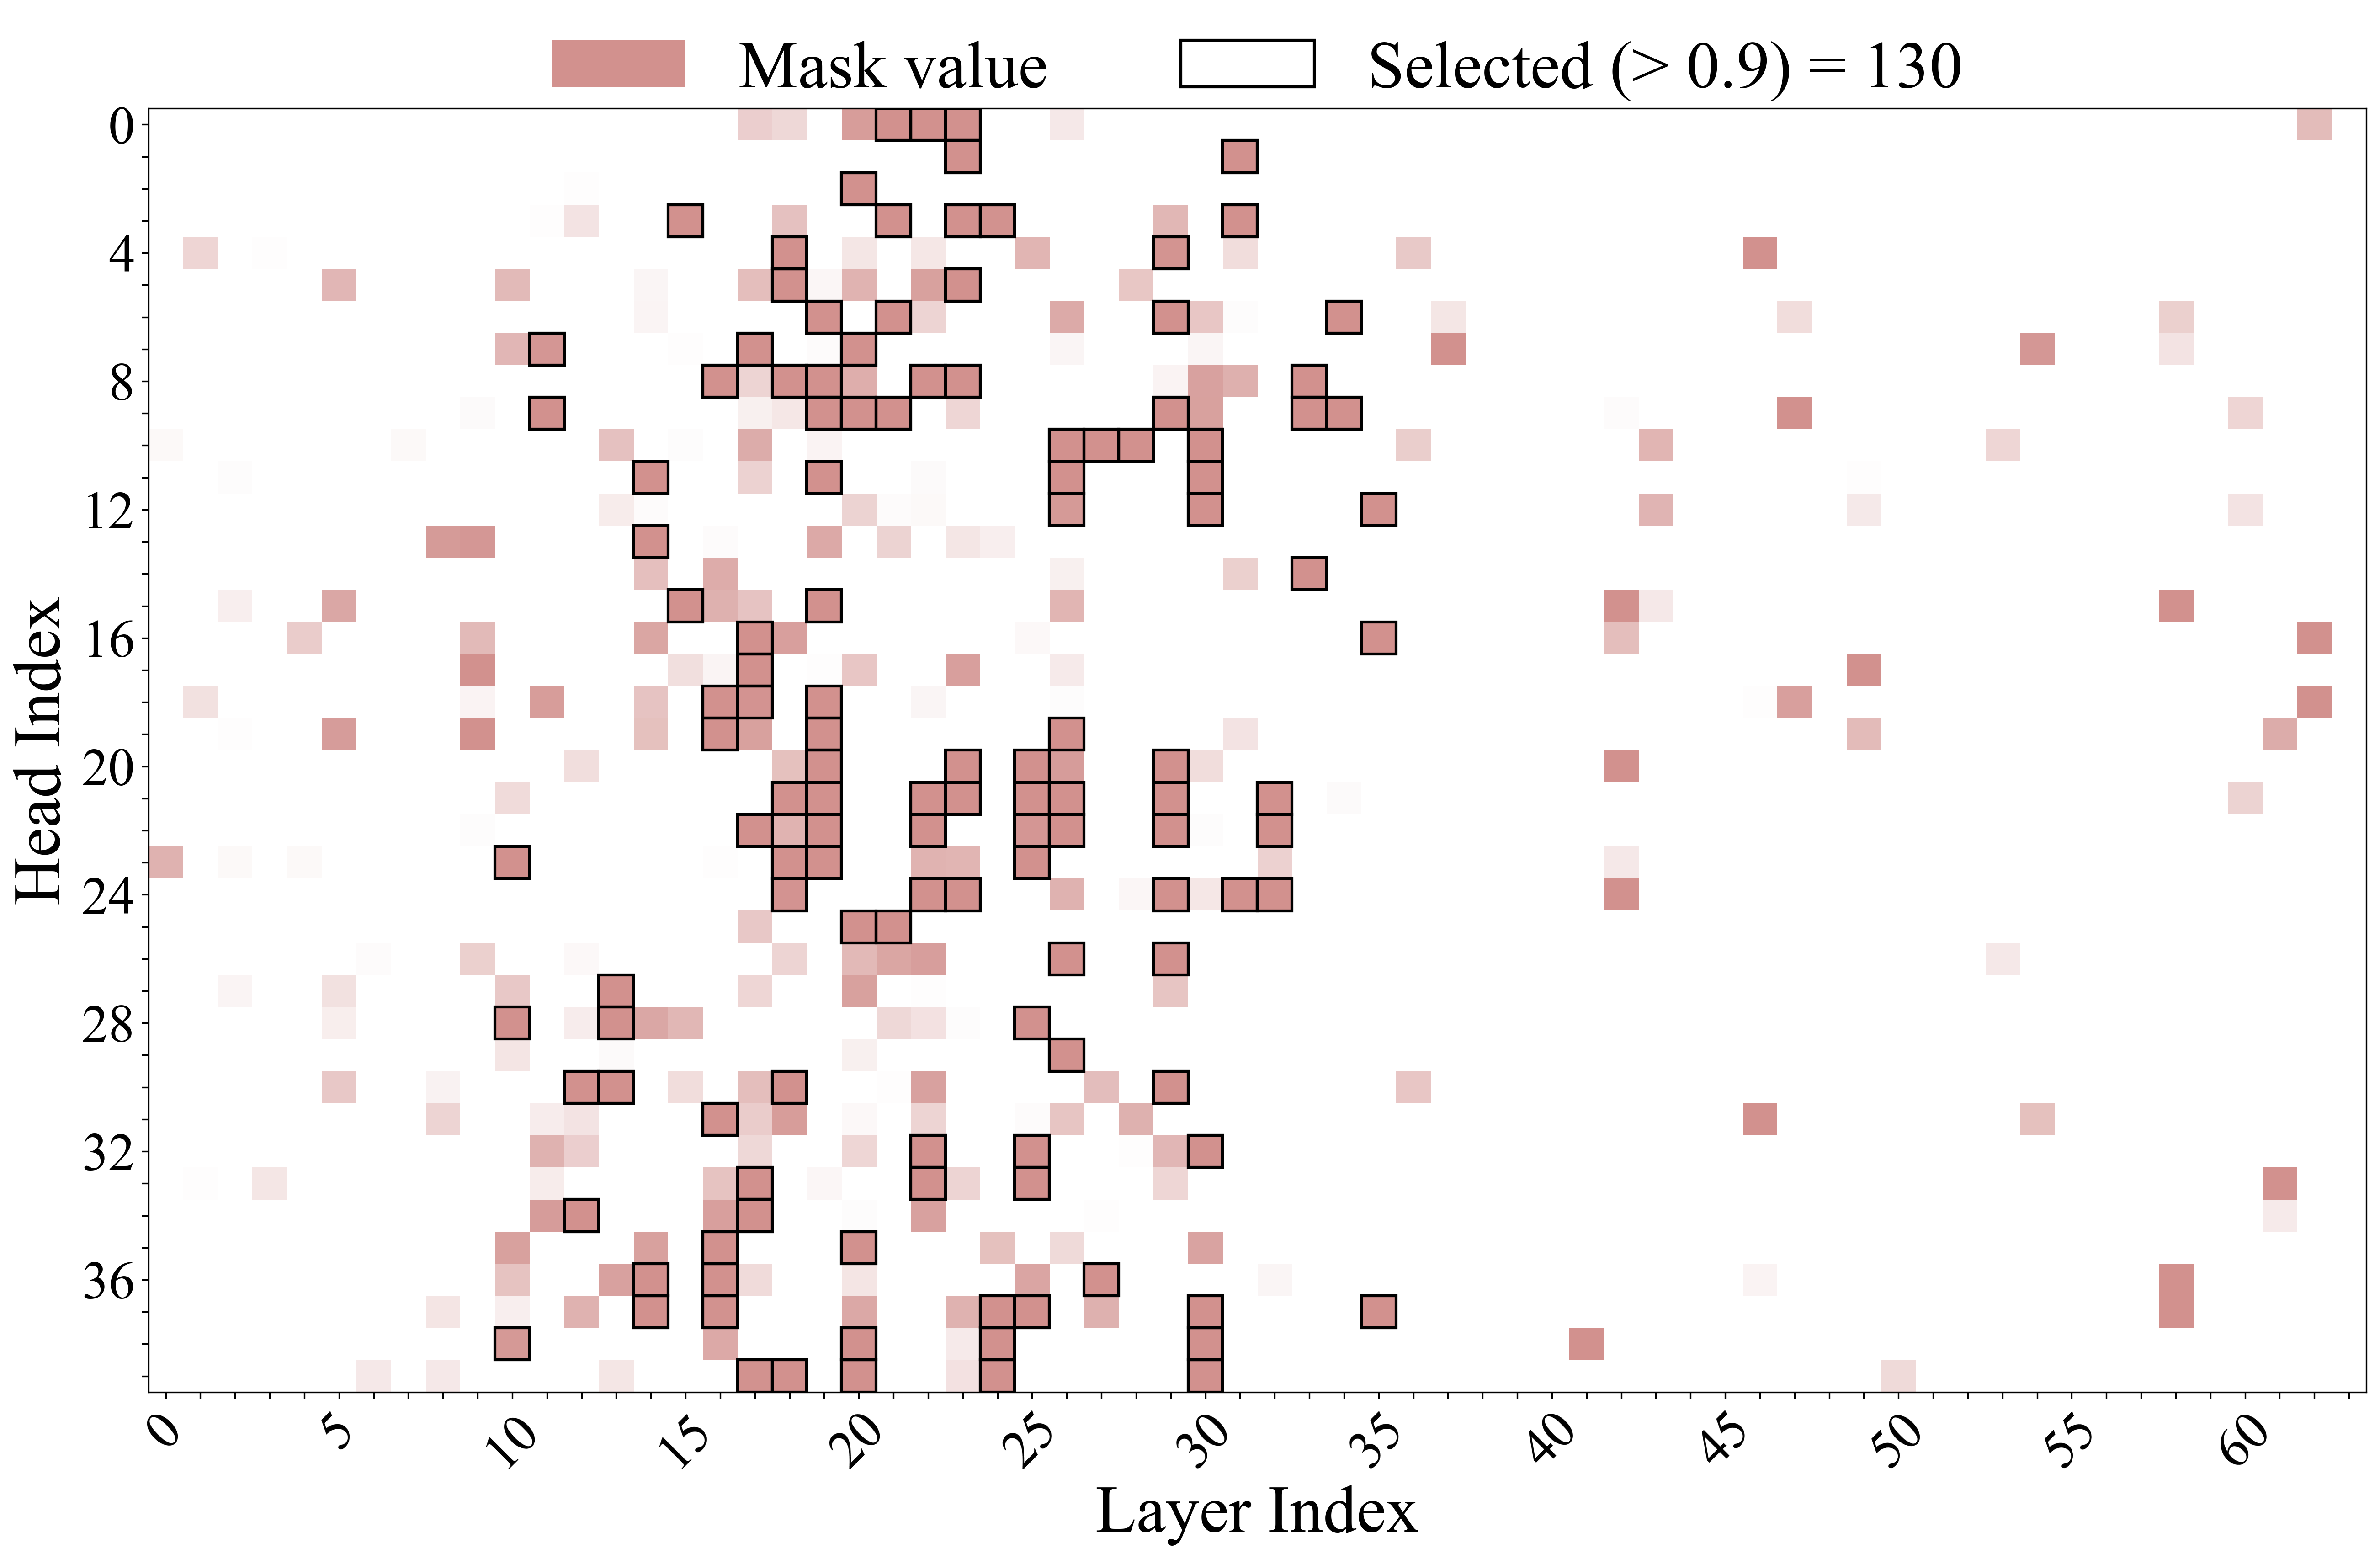

In [4]:
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from matplotlib import patches

plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 28
MEDIUM_SIZE = 35
BIGGER_SIZE = 40

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)


def get_ticks(ticks, skip=5, offset=0):
    ret = []
    for i in ticks:
        actual_layer = i + offset
        if actual_layer % skip == 0:
            ret.append(str(actual_layer))
        else:
            ret.append("")
    return ret


_n_heads = mt.config.num_attention_heads
_n_layer = mt.n_layer

# Build continuous mask matrix: shape (n_heads, n_layer)
# Layers outside the optimized range stay 0.
function_mask = torch.zeros((_n_heads, _n_layer), dtype=torch.float32)
for i, layer_idx in enumerate(goal_layers):
    function_mask[:, layer_idx] = gck["mask_values"][i]

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 12))

colors = ["white", "#BF625E"]
cmap = LinearSegmentedColormap.from_list("white_orange", colors, N=100)

ax.imshow(
    function_mask.numpy(),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=1,
    alpha=0.7,
)

# Black border around selected heads (mask value > 0.5)
for layer_idx, head_idx in goal_heads:
    rect = patches.Rectangle(
        (layer_idx - 0.5, head_idx - 0.5),
        1,
        1,
        linewidth=1.5,
        edgecolor="black",
        facecolor="none",
    )
    ax.add_patch(rect)

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(
    ticks=range(_n_layer),
    labels=get_ticks(range(_n_layer)),
    rotation=45,
)
plt.yticks(
    ticks=range(_n_heads),
    labels=get_ticks(range(_n_heads), skip=4),
)

legend_elements = [
    mpatches.Patch(facecolor="#BF625E", alpha=0.7, label="Mask value"),
    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        linewidth=1.5,
        label=f"Selected (> {GOAL_THRESHOLD}) = {len(goal_heads)}",
    ),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=2,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()


In [5]:
# ── the GoalScope design point (grid axes for the eventual script) ──

if MODEL_NAME == "Qwen/Qwen2.5-Coder-32B-Instruct":
    STEER_BAND = (35, 46)
elif MODEL_NAME == "meta-llama/Llama-3.3-70B-Instruct":
    STEER_BAND = (20, 40)
elif MODEL_NAME == "allenai/Olmo-3.1-32B-Instruct":
    # STEER_BAND = (15, 25)
    STEER_BAND = (35, 46)
else:
    raise ValueError(f"Set STEER_BAND for model {MODEL_NAME}")


GOALSCOPE_CONFIG = dict(
    selected_heads   = goal_heads,                  # <-- grid: which head set
    # strategy         = "additive", alpha=0.2,       # <-- grid: "additive" | "replace"
    strategy         = "replace", alpha=1.0,
    steer_layer_range= STEER_BAND,                    # <-- grid: additive-only injection layers
    n_steer_tokens   = "all",
    max_new_tokens   = 64,
)
print(GOALSCOPE_CONFIG)

{'selected_heads': [(10, 23), (10, 28), (10, 38), (11, 7), (11, 9), (12, 30), (12, 34), (13, 27), (13, 28), (13, 30), (14, 11), (14, 13), (14, 36), (14, 37), (15, 3), (15, 15), (16, 8), (16, 18), (16, 19), (16, 31), (16, 35), (16, 36), (16, 37), (17, 7), (17, 16), (17, 17), (17, 18), (17, 22), (17, 33), (17, 34), (17, 39), (18, 4), (18, 5), (18, 8), (18, 21), (18, 23), (18, 24), (18, 30), (18, 39), (19, 6), (19, 8), (19, 9), (19, 11), (19, 15), (19, 18), (19, 19), (19, 20), (19, 21), (19, 22), (19, 23), (20, 2), (20, 7), (20, 9), (20, 25), (20, 35), (20, 38), (20, 39), (21, 0), (21, 3), (21, 6), (21, 9), (21, 25), (22, 0), (22, 8), (22, 21), (22, 22), (22, 24), (22, 32), (22, 33), (23, 0), (23, 1), (23, 3), (23, 5), (23, 8), (23, 20), (23, 21), (23, 24), (24, 3), (24, 37), (24, 38), (24, 39), (25, 20), (25, 21), (25, 22), (25, 23), (25, 28), (25, 32), (25, 33), (25, 37), (26, 10), (26, 11), (26, 12), (26, 19), (26, 21), (26, 22), (26, 26), (26, 29), (27, 10), (27, 36), (28, 10), (29, 4

In [6]:
from src.tokens import prepare_input
from src.functional import generate_with_patch

messages = [
    {"role": "system", "content": "You are a helpful assistant proficient in programming."},
    {"role": "user", "content": "Write a mergesort code in Python. Just the code, no explanation and comments."},
    {"role": "assistant", "content": "\n<code>\n"},
]
dest_prompt = mt.tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=False,
    continue_final_message=True,
    tokenize=False,
    chat_template_kwargs={"enable_thinking": False},
)
dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")

clean_gen = generate_with_patch(
    mt,
    inputs=dest_tok,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


clean         <|im_start|>system
You are a helpful assistant proficient in programming.<|im_end|>
<|im_start|>user
Write a mergesort code in Python. Just the code, no explanation and comments.<|im_end|>
<|im_start|>assistant

<code>
def merge_sort(arr):
    if len(arr) <= 1:
        return arr
    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])
    return merge(left, right)

def merge(left, right):
    result = []
    i = j = 0
    while i < len(left) and j < len(right):
        if left[i] < right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1
    result.extend(left[i:])
    result.extend(right[j:])
    return result
</code>

In [7]:
from src.goals.goalscope import apply_goalscope

demo_goalscope = apply_goalscope(
    prompt=dest_prompt + clean_gen,
    mt=mt,
    title="GoalScope — TESTING",
    **GOALSCOPE_CONFIG,
)

GoalScope[replace]:   0%|          | 0/12 [00:00<?, ?it/s]

## 2. Corpus — `check_conditions(n: int)` with letters naming

Single-line-capable INT predicates so each condition is a clean one-liner `    a = <expr>`; letters
naming (`a`/`b`/`c`) matches how the goal heads were localized. We cut at the stub and greedy-decode
the whole body.

In [8]:
from src.goals.condition_data import (INT_PREDICATES, sample_specs, materialize)
from src.goals.functional import apply_chat_template, supports_chat_template
from src.tokens import prepare_input
from src.goals.goalscope import greedy_continue

N_SPECS, NUM_CONDITIONS, SEED = 5, [3, 4, 5], 321
_sl_preds = [p for p in INT_PREDICATES if p.has_singleline_for("python")]
print(f"{len(_sl_preds)}/{len(INT_PREDICATES)} INT predicates have a single-line python form")

_specs = sample_specs(N_SPECS, NUM_CONDITIONS, seed=SEED, predicates=_sl_preds, allow_repeats=False)
for j, sp in enumerate(_specs): sp.spec_id = f"eval_int_{j:02d}"
samples = materialize(_specs, langs=["python"], modularities=["monolithic"])
print(f"{len(samples)} samples:", [(s.spec.spec_id, s.spec.num_conditions) for s in samples])

def build_prompt(sample):
    instr = sample.render_instruction(name_rule="letters", multistep=False)   # mandates a/b/c
    stub  = sample.render_code_stub()                                          # def check_conditions(n: int):\n
    if supports_chat_template(mt):
        return apply_chat_template(mt=mt, user_query=instr.strip(), incomplete_code=stub)
    return instr + "\nAnswer:\n" + stub

print("\n" + "=" * 30 + " one prompt " + "=" * 30)
print(build_prompt(samples[0]))

23/23 INT predicates have a single-line python form
5 samples: [('eval_int_00', 4), ('eval_int_01', 4), ('eval_int_02', 3), ('eval_int_03', 5), ('eval_int_04', 3)]

============================== one prompt ==============================
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n has at least 3 digits
2. n is even
3. n is smaller than the number obtained by reversing its digits
4. the sum of n's digits is divisible by 5

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a

In [9]:
# greedy-decode the body for every sample (single pass each; keep it small for the sketch)
completions = {}
for s in samples:
    prompt = build_prompt(s)
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    completions[s.spec.spec_id] = greedy_continue(mt, **inp, max_new_tokens=256)

for s in samples:
    rich_print(f"\n[bold cyan]== {s.spec.spec_id}  preds={s.spec.predicate_ids} ==[/bold cyan]")
    rich_print(f"[grey58]{escape(' | '.join(s.spec.spec_texts))}[/grey58]")
    rich_print(f"[salmon1]{escape(s.render_code_stub() + completions[s.spec.spec_id])}[/salmon1]")

== eval_int_00  preds=['num_digits_ge', 'even', 'reversed_greater', 'digit_sum_divisible'] ==

n has at least 3 digits | n is even | n is smaller than the number obtained by reversing its digits | the sum of 
n's digits is divisible by 5

def check_conditions(n: int):
    a = len(str(n)) >= 3
    b = n % 2 == 0
    s = str(n)
    rev = int(s[::-1])
    c = n < rev
    d = sum(int(x) for x in s) % 5 == 0
    print(f"a={a} b={b} c={c} d={d} all={a and b and c and d}")
</code>

== eval_int_01  preds=['set_bits_gt', 'abundant', 'power_of_two', 'perfect_square'] ==

n has more than 1 ones in its binary representation | the sum of n's proper divisors is greater than n | n is a 
power of two | n is a perfect square

def check_conditions(n: int):
    a = bin(n).count('1') > 1
    b = sum(i for i in range(1, n) if n % i == 0) > n
    c = (n & (n - 1)) == 0 and n != 0
    d = int(n ** 0.5) ** 2 == n
    print(f"a: {a}, b: {b}, c: {c}, d: {d}")
    print(f"all: {a and b and c and d}")
</code>

... (5 outputs left out)

def check_conditions(n: int):
    a = str(n) == str(n)[::-1]
    b = n >= 1
    c = round(n ** (1/3)) ** 3 == n
    d = (n & (n - 1)) == 0 and n != 0
    e = n < int(str(n)[::-1])
    print(f"a: {a}, b: {b}, c: {c}, d: {d}, e: {e}")
    print(f"all: {a and b and c and d and e}")
</code>

== eval_int_04  preds=['reversed_greater', 'divisible', 'power_of_two'] ==

n is smaller than the number obtained by reversing its digits | n is divisible by 10 | n is a power of two

def check_conditions(n: int):
    a = n < int(str(n)[::-1])
    b = n % 10 == 0
    c = (n > 0) and (n & (n - 1)) == 0
    print(f"a: {a}, b: {b}, c: {c}, all: {a and b and c}")
</code>

## 3. Part (i) — oracle span labelling  *(which tokens implement which condition)*

`label_generation` (Claude oracle) segments the generation into per-condition spans — `gen_token_range`
(the implementation span) and `step_text` (the condition description). Renderer copied from `01_data §3`.

In [10]:
from src.goals.multistep_label import label_generation

PALETTE = ["green", "cyan", "magenta", "yellow", "blue", "bright_red",
           "bright_cyan", "bright_magenta", "bright_green"]
def _vis(s): return s.replace("\n", "↵\n").replace("\t", "⇥")

def render_oracle_labels(lab):
    combined = lab.full_prompt + lab.generation
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    ids = enc["input_ids"]; offs = [tuple(p) for p in enc["offset_mapping"]]
    char_off = len(lab.full_prompt)
    gen_start = next(j for j, (a, b) in enumerate(offs) if a >= char_off and b > a)
    gen_step, seg_start = {}, {}
    for i, sl in enumerate(lab.labels):
        if sl.gen_token_range:
            for t in range(*sl.gen_token_range): gen_step[t] = i
            seg_start.setdefault(sl.gen_token_range[0], i)
    sty = lambda i: f"black on {PALETTE[i % len(PALETTE)]}"
    txt = Text()
    for t in range(len(ids)):
        if t == gen_start:
            txt.append("\n" + "─" * 20 + " GENERATION " + "─" * 20 + "\n", style="bold grey42")
        if t in seg_start:
            txt.append(f"\n┌── cond {seg_start[t]} ──\n", style="bold yellow")
        s = _vis(mt.tokenizer.decode([ids[t]]))
        i = gen_step.get(t) if t >= gen_start else None
        txt.append(s, style=(sty(i) if i is not None else ("grey42" if t < gen_start else "grey58")))
    console.print(txt)
    tb = Table(title="oracle step labels", show_lines=True)
    for col, w in [("cond", 4), ("condition", 40), ("gen tok", 12), ("gen_code", 44)]:
        tb.add_column(col, overflow="fold", max_width=w)
    for i, sl in enumerate(lab.labels):
        tb.add_row(str(i), sl.step_text, str(sl.gen_token_range), _vis(sl.gen_code))
    console.print(tb)

# label every sample (cached); keep the LabeledGeneration around for eval
labels_by_id = {}
for s in samples:
    prompt = build_prompt(s)
    lab = label_generation(mt, s, prompt, completions[s.spec.spec_id], use_cache=True)
    labels_by_id[s.spec.spec_id] = lab
    print(f"labeled {s.spec.spec_id}: {len(lab.labels)} conditions")

labeled eval_int_00: 4 conditions
labeled eval_int_01: 4 conditions
labeled eval_int_02: 3 conditions
labeled eval_int_03: 5 conditions
labeled eval_int_04: 3 conditions


In [11]:
demo_sample = samples[0]
render_oracle_labels(labels_by_id[demo_sample.spec.spec_id])

<|im_start|>system↵
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>↵
<|im_start|>user↵
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:↵
↵
1. n has at least 3 digits↵
2. n is even↵
3. n is smaller than the number obtained by reversing its digits↵
4. the sum of n's digits is divisible by 5↵
↵
For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.↵
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.↵
Do not include any comments in your code.<|im_end|>↵
<|im_start|>assistant↵
<code>↵
def check_conditions(n: int):↵

──────────────────── GENERATION ────────────────────

┌── cond 0 ──
    a = len(str(n)) >= 3↵

┌── cond 1 ──
    b = n % 2 == 0↵

┌── cond 2 ──
    s = str(n)↵
    rev = int(s[::-1])↵
    c = n < rev↵

┌── cond 3 ──
    d = sum(int(x) for x in s) % 5 == 0↵
    print(f"a={a} b={b} c={c} d={d} all={a and b and c and d}")↵
</code>

                                            oracle step labels                                             
┏━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ cond ┃ condition                                ┃ gen tok    ┃ gen_code                                 ┃
┡━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 0    │ n has at least 3 digits                  │ (241, 252) │     a = len(str(n)) >= 3↵                │
│      │                                          │            │                                          │
├──────┼──────────────────────────────────────────┼────────────┼──────────────────────────────────────────┤
│ 1    │ n is even                                │ (252, 263) │     b = n % 2 == 0↵                      │
│      │                                          │            │                                          │
├──────┼──────────────────────────────────────────┼────────────┼──────────────────────────────────────────┤
│ 2    │ n is smaller than the number obtained by │ (263, 284) │     s = str(n)↵                          │
│      │ reversing its digits                     │            │     rev = int(s[::-1])↵                  │
│      │                                          │            │     c = n < rev↵                         │
│      │                                          │            │                                          │
├──────┼──────────────────────────────────────────┼────────────┼──────────────────────────────────────────┤
│ 3    │ the sum of n's digits is divisible by 5  │ (284, 303) │     d = sum(int(x) for x in s) % 5 == 0↵ │
│      │                                          │            │                                          │
└──────┴──────────────────────────────────────────┴────────────┴──────────────────────────────────────────┘

## 4. GoalScope read-outs per token position

`apply_goalscope` over the full `prompt + generation`. Returns one dict per code token
(`pos`, `token`, `patched_gen`). We keep the HTML viz for eyeballing and index results by `pos`.

In [12]:
from src.goals.goalscope import apply_goalscope

def run_goalscope(sample, show=True):
    full_text = build_prompt(sample) + completions[sample.spec.spec_id]
    res = apply_goalscope(full_text, mt=mt, show=show, include_noncode=False,
                          title=f"GoalScope · {sample.spec.spec_id}", **GOALSCOPE_CONFIG)
    return full_text, {r["pos"]: r for r in res}

demo_full, demo_readouts = run_goalscope(demo_sample, show=True)
print(f"{len(demo_readouts)} scoped code positions")

GoalScope[replace]:   0%|          | 0/7 [00:00<?, ?it/s]

105 scoped code positions


## 5. Anchor positions per assignment line

For each condition's result var, locate its assignment line `    {var} = …` in the **same
tokenization GoalScope used** (`prepare_input(full_text)` offsets) and pull four anchor tokens:

| anchor | token | intuition |
|---|---|---|
| `var` | `a` / `b` / `c` | the model names the target it is about to compute |
| `eq` | `=` | commitment point — about to emit the RHS |
| `first_impl` | first RHS token after `=` | the model has started the implementation |
| `indent` | line's leading whitespace (your "−1") | just entered the line |
| `prev_end` | newline ending the previous line (your "−2") | just finished the previous condition |

Each anchor maps to a condition `k` (matched by var name) → its oracle span + description.

In [13]:
from src.tokens import find_token_range

def _tok_at_char(offsets, cpos):
    for ti, (a, b) in enumerate(offsets):
        if a <= cpos < b: return ti
    return None

def line_anchors(full_text, offsets, var, gen_char_start):
    """Token positions of {var, eq, first_impl, indent, prev_end} for the line `    {var} = ...`
    found in full_text at/after gen_char_start. Returns {} if the line isn't found."""
    m = re.search(rf"(?m)^([ \t]*){re.escape(var)}\s*=", full_text[gen_char_start:])
    if not m: return {}
    base = gen_char_start + m.start()
    indent_c = base                                   # first whitespace char of the line
    var_c    = base + len(m.group(1))                 # where `var` starts
    eq_c     = gen_char_start + m.start() + m.group(0).rfind("=")
    prev_nl  = full_text.rfind("\n", 0, base)         # newline that ends the previous line
    out = {}
    out["var"]    = _tok_at_char(offsets, var_c)
    out["eq"]     = _tok_at_char(offsets, eq_c)
    out["first_impl"] = (out["eq"] + 1 if out["eq"] is not None and out["eq"] + 1 < len(offsets) else None)  # first RHS token after `=`
    out["indent"] = _tok_at_char(offsets, indent_c) if full_text[indent_c] in " \t" else out["var"]
    out["prev_end"] = _tok_at_char(offsets, prev_nl) if prev_nl != -1 else None
    return {k: v for k, v in out.items() if v is not None}

def anchors_for_sample(sample, full_text):
    """list of dicts: {cond, var, condition, impl_span, anchors:{name->pos}}."""
    lab = labels_by_id[sample.spec.spec_id]
    enc = prepare_input(prompts=full_text, tokenizer=mt, return_offsets_mapping=True)
    offsets = [tuple(p) for p in enc.pop("offset_mapping")[0].tolist()]
    gen_char_start = len(build_prompt(sample))
    # var name per condition (letters): a, b, c, ... in order
    out = []
    for k, sl in enumerate(lab.labels):
        var = chr(97 + k)
        a = line_anchors(full_text, offsets, var, gen_char_start)
        out.append(dict(cond=k, var=var, condition=sl.step_text,
                        impl_span=sl.gen_code.strip(), anchors=a))
    return out, offsets

demo_anchors, demo_offsets = anchors_for_sample(demo_sample, demo_full)
_at = Table(title=f"anchors · {demo_sample.spec.spec_id}", show_lines=True)
for c in ["cond", "var", "anchor", "pos", "token", "read-out"]:
    _at.add_column(c, overflow="fold", max_width=(48 if c == "read-out" else 20))
for row in demo_anchors:
    for aname, pos in row["anchors"].items():
        ro = demo_readouts.get(pos, {}).get("patched_gen", "—")
        _at.add_row(str(row["cond"]), row["var"], aname, str(pos),
                    escape(_vis(demo_readouts.get(pos, {}).get("token", "?"))),
                    escape(ro[:80]))
rich_print(_at)

                                   anchors · eval_int_00                                    
┏━━━━━━┳━━━━━┳━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ cond ┃ var ┃ anchor     ┃ pos ┃ token ┃ read-out                                         ┃
┡━━━━━━╇━━━━━╇━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 0    │ a   │ var        │ 242 │  a    │ I can't see the code or its context. Please      │
│      │     │            │     │       │ provide the code and specify what yo             │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 0    │ a   │ eq         │ 243 │  =    │ I cannot determine the number of digits in a     │
│      │     │            │     │       │ number without converting it to a s              │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 0    │ a   │ first_impl │ 244 │  len  │ I'm checking if the number has at least three    │
│      │     │            │     │       │ digits.                                          │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 0    │ a   │ indent     │ 241 │       │ I cannot answer without seeing the code and the  │
│      │     │            │     │       │ specific line in question. Pleas                 │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 0    │ a   │ prev_end   │ 240 │ ):↵   │ I cannot answer without seeing the code. Please  │
│      │     │            │     │       │ provide the code for context.                    │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ var        │ 253 │  b    │ I can't answer without the specific code and     │
│      │     │            │     │       │ context. Please provide the line an              │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ eq         │ 254 │  =    │ Declaring a variable to check if a number is     │
│      │     │            │     │       │ even.                                            │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ first_impl │ 255 │  n    │ I'm checking if a number is even by seeing if    │
│      │     │            │     │       │ it's divisible by 2.                             │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ indent     │ 252 │       │ I cannot provide an answer without the specific  │
│      │     │            │     │       │ code and context. Please provide                 │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ prev_end   │ 251 │ ↵     │ I cannot answer without knowing the specific     │
│      │     │            │     │       │ line of code in question. Please pr              │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 2    │ c   │ var        │ 278 │  c    │ I cannot see the code or its context. Please     │
│      │     │            │     │       │ provide the code and clarify the li              │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 2    │ c   │ eq         │ 279 │  =    │ I cannot determine if a number is greater than   │
│      │     │            │     │       │ another without the actual values                │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 2    │ c   │ first_impl │ 280 │  n    │ I cannot determine if a number is greater than   │
│      │     │            │     │       │ another without executing the com                │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│

### 5b. Rule-based impl-span (no oracle) for `naming="letters"`

With letters naming the body is deterministic — `    a = … / b = … / c = … / print(…)` — so a
condition's implementation is just the code between its own `<letter> =` line and the **next**
letter's line (and for the last letter, up to the terminal `print`/`return`). No `label_generation`
needed. Below we compare this rule against the oracle `gen_code` spans; if agreement is high we wire
`rule_based_spans` into the eval script to drop the oracle span-labelling step.

> Why? To save some money on API calls.

In [14]:
def rule_based_spans(full_text, gen_char_start, n_conditions):
    """Per-condition impl_span for naming="letters", purely rule-based.
    span[k] = code between `<letter_k> =` and the next present `<letter> =` line; for the last
    present letter, up to the terminal print/return. Returns list[str|None] (None if not found)."""
    gen = full_text[gen_char_start:]
    starts = []
    for k in range(n_conditions):
        letter = chr(97 + k)
        m = re.search(rf"(?m)^[ \t]*{re.escape(letter)}\s*=(?!=)", gen)   # assignment, not `==`
        starts.append(m.start() if m else None)
    present = [s for s in starts if s is not None]
    if not present:
        return [None] * n_conditions
    last_start = max(present)
    mterm = re.search(r"(?m)^[ \t]*(?:print|return)\b", gen[last_start:])  # terminal statement
    term = last_start + mterm.start() if mterm else len(gen)
    spans = []
    for k in range(n_conditions):
        s = starts[k]
        if s is None:
            spans.append(None); continue
        later = [t for t in starts[k + 1:] if t is not None and t > s]
        e = min(later) if later else term
        spans.append(gen[s:e].strip())
    return spans

In [15]:
# ── rule-based vs oracle impl_span, over all samples ──
def _norm(s): return re.sub(r"\s+", " ", (s or "").strip())

_ct = Table(title="rule-based vs oracle impl_span (naming='letters')", show_lines=True)
for c in ["spec", "cond", "var", "rule-based span", "oracle span", "match"]:
    _ct.add_column(c, overflow="fold", max_width=(30 if "span" in c else 12))
n_match = n_tot = 0
for s in samples:
    prompt = build_prompt(s)
    ft = prompt + completions[s.spec.spec_id]
    lab = labels_by_id[s.spec.spec_id]
    rspans = rule_based_spans(ft, len(prompt), len(lab.labels))
    for k, sl in enumerate(lab.labels):
        rb, orc = rspans[k], sl.gen_code.strip()
        m = _norm(rb) == _norm(orc)
        n_tot += 1; n_match += int(m)
        _ct.add_row(s.spec.spec_id, str(k), chr(97 + k),
                    escape(_vis(rb or "—")), escape(_vis(orc)),
                    "[green]OK[/green]" if m else "[red]DIFF[/red]")
rich_print(_ct)
print(f"exact-match (whitespace-normalized): {n_match}/{n_tot} = {n_match/max(n_tot,1):.0%}")

                          rule-based vs oracle impl_span (naming='letters')                           
┏━━━━━━━━━━━━━┳━━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ spec        ┃ cond ┃ var ┃ rule-based span                ┃ oracle span                    ┃ match ┃
┡━━━━━━━━━━━━━╇━━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ eval_int_00 │ 0    │ a   │ a = len(str(n)) >= 3           │ a = len(str(n)) >= 3           │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_00 │ 1    │ b   │ b = n % 2 == 0↵                │ b = n % 2 == 0                 │ DIFF  │
│             │      │     │     s = str(n)↵                │                                │       │
│             │      │     │     rev = int(s[::-1])         │                                │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_00 │ 2    │ c   │ c = n < rev                    │ s = str(n)↵                    │ DIFF  │
│             │      │     │                                │     rev = int(s[::-1])↵        │       │
│             │      │     │                                │     c = n < rev                │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_00 │ 3    │ d   │ d = sum(int(x) for x in s) % 5 │ d = sum(int(x) for x in s) % 5 │ OK    │
│             │      │     │ == 0                           │ == 0                           │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_01 │ 0    │ a   │ a = bin(n).count('1') > 1      │ a = bin(n).count('1') > 1      │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_01 │ 1    │ b   │ b = sum(i for i in range(1, n) │ b = sum(i for i in range(1, n) │ OK    │
│             │      │     │ if n % i == 0) > n             │ if n % i == 0) > n             │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_01 │ 2    │ c   │ c = (n & (n - 1)) == 0 and n   │ c = (n & (n - 1)) == 0 and n   │ OK    │
│             │      │     │ != 0                           │ != 0                           │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_01 │ 3    │ d   │ d = int(n ** 0.5) ** 2 == n    │ d = int(n ** 0.5) ** 2 == n    │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_02 │ 0    │ a   │ a = n >= 10↵                   │ a = n >= 10                    │ DIFF  │
│             │      │     │     s = str(n)                 │                                │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_02 │ 1    │ b   │ b = all(int(c) != 0 for c in   │ b = all(int(c) != 0 for c in   │ OK    │
│             │      │     │ s)                             │ s)                             │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_02 │ 2    │ c   │ c = gcd(n, 10) == 1            │ c = gcd(n, 10) == 1            │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_03 │ 0    │ a   │ a = str(n) == str(n)[::-1]     │ a = str(n) == str(n)[::-1]     │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_03 │ 1    │ b   │ b = n >= 1                     │ b = n >= 1                     │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼─────────────────────────

exact-match (whitespace-normalized): 16/19 = 84%


## 6. Soft eval — closed-set **likelihood over the full patched readout** (no oracle)

The patch's influence plays out over the *whole* autoregressive generation, so we score the actual
`max_new_tokens` readout GoalScope produces (identical to the viz) instead of teacher-forcing a short
reference at the answer-start — where the goal signal barely moves the first token, which is why the
earlier keyword-LL diverged from the viz and hard-eval.

`soft_from_readout` computes, non-oracle, the model's closed-set likelihood `p(reference_k | readout)`
over all predicates and reports `p_true` for the predicate the code implements (`spec.predicate_ids[k]`).
Because it reads the *same* generated text hard-eval reads, the two now track each other; the patch's
influence is identical to the viz because it **is** the viz generation.

`candidate_lls_under_patch` (teacher-forcing a short reference *under the patch*) is kept as a direct
signal probe — the demo prints both side by side so you can see the gap. Candidate text still comes
from `id_substrs` (placeholders stripped); `REF_SOURCE="spec"` is available.

In [16]:
# ── §6: likelihood-based soft eval — closed set over ALL predicates, under the GoalScope patch ──
import baukit
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.goals.goalscope import _build_goalscope_prompt

REF_SOURCE = "id_substrs"  # "id_substrs" (placeholders stripped) | "spec" (spec_template, stripped)


def predicate_reference_text(pred, source=REF_SOURCE):
    if source == "spec":
        t = re.sub(r"\{[^}]*\}", "", pred.spec_template)
        return re.sub(r"\s+", " ", t).strip(" .")
    return " ".join(s for s in pred.id_substrs if "{" not in s)  # drop {a}/{b}/{k}/{t}


# candidate set = every predicate of the working datatype (int), fixed order
ALL_PREDS = INT_PREDICATES
PRED_IDS = [p.id for p in ALL_PREDS]
PRED_REF = [predicate_reference_text(p) for p in ALL_PREDS]
PRED_TOK = [
    mt.tokenizer(" " + t, add_special_tokens=False)["input_ids"] for t in PRED_REF
]  # leading space = continues the answer
_PROBE_IDS = prepare_input(prompts=_build_goalscope_prompt(mt), tokenizer=mt)[
    "input_ids"
][0].tolist()
print(
    f"{len(ALL_PREDS)} candidate predicates (REF_SOURCE={REF_SOURCE!r}); e.g.",
    list(zip(PRED_IDS[:5], PRED_REF[:5])),
)


@torch.no_grad()
def candidate_lls_under_patch(steering_vec, alpha, steer_layers, length_norm=True):
    """(n_pred,) length-normalized log p of each predicate reference as the probe answer, with
    `alpha*steering_vec` added at every answer-predicting position on `steer_layers` (mirrors
    GoalScope's per-step -1 injection). One padded forward over all candidates."""
    dev = next(mt._model.parameters()).device
    P = len(_PROBE_IDS)
    seqs = [_PROBE_IDS + t for t in PRED_TOK]
    maxlen = max(len(s) for s in seqs)
    pad = (
        mt.tokenizer.pad_token_id
        if mt.tokenizer.pad_token_id is not None
        else mt.tokenizer.eos_token_id
    )
    ids = torch.full((len(seqs), maxlen), pad, dtype=torch.long)
    attn = torch.zeros((len(seqs), maxlen), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, : len(s)] = torch.tensor(s)
        attn[i, : len(s)] = 1
    ids, attn = ids.to(dev), attn.to(dev)
    sv = (alpha * steering_vec).to(dev)
    layer_names = [mt.layer_name_format.format(l) for l in steer_layers]

    def _edit(output, layer):  # baukit edit_output(output, layer)
        is_tuple = isinstance(output, tuple)
        h = output[0] if is_tuple else output
        h[:, P - 1 :, :] = h[:, P - 1 :, :] + sv.to(
            device=h.device, dtype=h.dtype
        )  # inject over the answer region
        return (h,) + output[1:] if is_tuple else h

    with baukit.TraceDict(mt._model, layer_names, edit_output=_edit):
        logits = mt._model(input_ids=ids, attention_mask=attn).logits.float()
    logp = torch.log_softmax(logits, dim=-1)  # (n, seq, vocab)

    lls = []
    for i, t in enumerate(PRED_TOK):
        pos = torch.arange(
            P - 1, P - 1 + len(t), device=logp.device
        )  # position j predicts answer token j
        tgt = torch.tensor(t, device=logp.device)
        s = logp[i, pos, tgt].sum()
        lls.append(float((s / len(t) if length_norm else s).cpu()))
    return np.array(lls)


def soft_metrics_ll(lls, true_pred_id, tau=1.0):
    lls = np.asarray(lls, float)
    p = np.exp((lls - lls.max()) / tau)
    p = p / p.sum()
    ti = PRED_IDS.index(true_pred_id)
    order = np.argsort(-lls)
    rank = int(np.where(order == ti)[0][0]) + 1
    return dict(
        p_true=float(p[ti]),
        rank_true=rank,
        argmax_id=PRED_IDS[int(order[0])],
        redirected=bool(order[0] == ti),
    )


def _readout_classifier_ctx(readout):
    msgs = [
        {"role": "user", "content":
            "A model was asked what a line of Python code is doing and answered:\n\n"
            f'"{readout.strip()}"\n\n'
            "Based only on that answer, name the single property of the number n that the code is "
            "checking. Reply with just the property."},
        {"role": "assistant", "content": ""},
    ]
    return mt.tokenizer.apply_chat_template(
        msgs, tokenize=False, add_generation_prompt=False, continue_final_message=True)

@torch.no_grad()
def soft_from_readout(readout, true_pred_id, length_norm=True):
    """Closed-set LM likelihood over the FULL patched readout: p(reference_k | readout), softmaxed
    over all predicates. Unpatched forward — the patch already shaped `readout` (== the viz gen).
    Returns a soft_metrics_ll-style dict."""
    if not readout or not readout.strip():
        return dict(p_true=float("nan"), rank_true=len(ALL_PREDS), argmax_id=None, redirected=False)
    dev = next(mt._model.parameters()).device
    ctx = prepare_input(prompts=_readout_classifier_ctx(readout), tokenizer=mt)["input_ids"][0].tolist()
    C = len(ctx)
    seqs = [ctx + t for t in PRED_TOK]
    maxlen = max(len(s) for s in seqs)
    pad = mt.tokenizer.pad_token_id if mt.tokenizer.pad_token_id is not None else mt.tokenizer.eos_token_id
    ids = torch.full((len(seqs), maxlen), pad, dtype=torch.long)
    attn = torch.zeros((len(seqs), maxlen), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s); attn[i, :len(s)] = 1
    logits = mt._model(input_ids=ids.to(dev), attention_mask=attn.to(dev)).logits.float()
    logp = torch.log_softmax(logits, dim=-1)
    lls = []
    for i, t in enumerate(PRED_TOK):
        pos = torch.arange(C - 1, C - 1 + len(t), device=logp.device)
        tgt = torch.tensor(t, device=logp.device)
        lls.append(float((logp[i, pos, tgt].sum() / (len(t) if length_norm else 1)).cpu()))
    return soft_metrics_ll(np.array(lls), true_pred_id)

# demo: readout-based soft (used by the driver) vs under-patch probe, on the `eq` anchor
assert GOALSCOPE_CONFIG["strategy"] == "additive", "under-patch probe supports additive strategy only"
_demo_src = prepare_input(prompts=demo_full, tokenizer=mt)
_apos = sorted({p for row in demo_anchors for p in row["anchors"].values()})
_svs = collect_head_steering_vecs(mt, _demo_src, GOALSCOPE_CONFIG["selected_heads"], token_positions=_apos)[0]
_svby = {p: _svs[i] for i, p in enumerate(_apos)}
_slay = list(range(*GOALSCOPE_CONFIG["steer_layer_range"]))
for row in demo_anchors:
    pos = row["anchors"].get("eq")
    if pos is None:
        continue
    true_id = demo_sample.spec.predicate_ids[row["cond"]]
    ro = demo_readouts.get(pos, {}).get("patched_gen", "")
    m_read = soft_from_readout(ro, true_id)
    m_probe = soft_metrics_ll(candidate_lls_under_patch(_svby[pos], GOALSCOPE_CONFIG["alpha"], _slay), true_id)
    print(f"[{row['cond']}] true={true_id:20s} readout p_true={m_read['p_true']:.3f}(r{m_read['rank_true']},argmax={m_read['argmax_id']})"
          f"  |  probe p_true={m_probe['p_true']:.3f}(r{m_probe['rank_true']})")
    print(f"      readout: {ro[:90]!r}")


23 candidate predicates (REF_SOURCE='id_substrs'); e.g. [('positive', 'positive'), ('le_bound', 'less than or equal'), ('ge_bound', 'greater than or equal'), ('in_range', 'between'), ('even', 'even')]


AssertionError: under-patch probe supports additive strategy only

## 7. Hard eval — oracle YES/NO faithfulness vs the *implementation span*

Reference = the actual code the model wrote for this condition (`gen_code`). Oracle asks: is the
read-out a faithful description of *this code*? YES / NO / NO_INFO / MALFORMED — the analog of
`09 §7`, roles swapped (truth is the implementation). Also a closed-set K-way assignment: which of
the example's conditions does the read-out best name? (redirect / accuracy).

Both graders are **imported from `scripts/evaluation/eval_goalscope.py`** rather than redefined here,
so this preview cannot drift from the real runs: the oracle is instructed to wrap its answer in
`<verdict>{ans}</verdict>` tags and the parser reads that tag (falling back to the last bare verdict
token, else `UNPARSED`). Edit the script to change a rubric.


In [17]:
# ── grading oracle: IMPORTED from scripts/evaluation/eval_goalscope.py (single source of truth) ──
# `hard_faithfulness` and `kway_assign` ARE the script's functions, so this preview and the real runs
# grade identically: same rubric (ending in the "<verdict>{ans}</verdict>" instruction), same verdict
# parser (tag first, then last bare token, else UNPARSED), same max_tokens, same model — therefore
# the same ask_claude cache entries too. To change a rubric or a token budget, edit the script;
# there is deliberately nothing to override here.
import hashlib
from functools import partial

from src.utils.oracle_llms import ask_claude          # only for the ad-hoc re-query cell in §8
from scripts.evaluation.eval_goalscope import (
    FAITH_HARD_SYS, ORACLE_MODEL, _KWAY_SYS, hard_eval, kway_assign,
)

# hard_eval(readout, impl_span, mode) -> dict(verdict, prompt, system, response), where
# verdict in {YES, NO, NO_INFO, MALFORMED, UNPARSED} and prompt/response are None for an empty
# read-out (no oracle call). The causality rubric is the same function with mode="causality".
hard_faithfulness = partial(hard_eval, mode="faithfulness")

HARD_SYS = FAITH_HARD_SYS   # for inspection/printing only — grading reads the script's own copy
KWAY_MAX_TOKENS = 256       # mirrors the script's kway_assign budget (it is part of the cache key)

assert "<verdict>{ans}</verdict>" in HARD_SYS, "rubric lost the <verdict> tag contract"
# the script stamps this same md5 into each run's config as `hard_rubric_tag`, so you can match a
# preview here against a saved run dir
print(f"grading oracle: {ORACLE_MODEL} | hard_rubric_tag "
      f"{hashlib.md5(HARD_SYS.encode()).hexdigest()[:8]}")


# demo on the `eq` anchor
_conds = [r["condition"] for r in demo_anchors]
for row in demo_anchors:
    pos = row["anchors"].get("eq")
    ro = demo_readouts.get(pos, {}).get("patched_gen", "")
    hv = hard_faithfulness(ro, row["impl_span"])
    kv = kway_assign(ro, _conds)
    print(f"read-out={ro!r}")
    print(f"[{row['cond']}] hard(vs `{row['impl_span']}`) = {hv['verdict']}   "
          f"kway->{kv['pred']} (true {row['cond']})")
    print(f"     hard oracle resp: {hv['response']!r}")
    print(f"     kway oracle resp: {kv['response']!r}")


grading oracle: claude-sonnet-4-6 | hard_rubric_tag 15dba839
2026-08-05 17:24:23 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:24:24 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
read-out='I cannot determine the number of digits in a number without converting it to a string and checking its length.'
[0] hard(vs `a = len(str(n)) >= 3`) = YES   kway->None (true 0)
     hard oracle resp: '<verdict>YES</verdict>'
     kway oracle resp: '-1'
2026-08-05 17:24:25 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:24:26 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
read-out='Declaring a variable to check if a number is even.'
[1] hard(vs `b = n % 2 == 0`) = YES   kway->1 (true 1)
     hard oracle resp: '<verdict>YES</verdict>'
     kway oracle resp: '1'
2026-08-05 17:24:27 httpx INFO     HTTP Reque

In [18]:
resp = hard_faithfulness(
    readout="Checking if n is a power of 3",
    impl_span="n % 3 == 0",
)
rich_print(resp)

2026-08-05 17:24:34 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


{
    'verdict': 'YES',
    'prompt': 'Code: n % 3 == 0\nDescription: Checking if n is a power of 3\nAnswer:',
    'system': "You are grading a lightweight interpretability probe (a patchscope). The DESCRIPTION below was read 
out of a model's hidden state at a SINGLE token while the model was writing one line of Python CODE that checks 
some property of its input. Because it is squeezed out of one token under a steering/patching setup, the 
description is usually NOISY: it may be wrapped in chat scaffolding (like 'Sure, but first let us ...'), contain 
code fences or half-written code, be cut off mid-sentence, or repeat and loop. Look PAST all of that surface noise 
and grade only the SUBSTANCE.\n\nThe question: does the description surface ANYTHING genuinely relevant to what the
CODE is doing — any relevant operation, quantity, sub-step, or property of the input? Pulling even a small correct 
fragment out of a single token is a SUCCESS, so grade as leniently as possible.\n\nThe following do NOT count 
against the description (still YES):\n  - Wrong specifics: a wrong constant, threshold, bound, modulus, operator, 
or comparison. If the code computes some quantity and compares it to a value, naming the quantity alone is enough 
and the exact value can be wrong or missing. Example: the code implements `average temperature > 30`; a read-out 
about `computing the average temperature` is YES even though the `> 30` part is wrong or absent.\n  - Wrong 
implementation nuance: naming a different mechanism for the same idea. Example: the read-out says `sorting with 
bubble sort` while the code calls .sort() or uses quicksort -> still YES.\n  - Broken, repetitive, or looping text,
AS LONG AS the repeated content is relevant. Example: a read-out that keeps repeating the correct operation is YES,
not MALFORMED.\n  - Partial coverage: naming just one relevant ingredient of a multi-part check counts.\n\nAnswer 
with exactly one token:\n  YES        - the description contains SOME content genuinely relevant to what the code 
does, however partial, imprecise, or garbled.\n  NO         - the description is coherent and about a specific 
thing, but that thing is UNRELATED to what the code does.\n  NO_INFO    - the description is coherent but too 
generic to indicate any specific aspect of the code (e.g. just 'doing a computation on the number').\n  MALFORMED  
- the description is contentless: empty, pure punctuation or garbage, or repetition that carries NO relevant 
meaning.\n\nGrade on meaning, not on shared keywords. Output only YES, NO, NO_INFO, or MALFORMED.\nPut your final 
answer inside <verdict>{ans}</verdict> tags, with no other text or explanation, to facilitate automated parsing.",
    'response': 'The code checks if n is divisible by 3 (n % 3 == 0), while the description says "checking if n is 
a power of 3." These are related but different operations — both involve the number 3 and properties of n with 
respect to 3.\n\n<verdict>YES</verdict>'
}

## 8. End-to-end driver + small scale-up + per-anchor summary

`eval_example` runs GoalScope once, walks every (condition, anchor), and scores soft + hard + kway.
Aggregating over a few examples answers the sketch's real question: **which anchor position yields
the most faithful read-outs?** — the row the grid-search script will later cross with
`{heads, alpha, strategy, layer_range}`.

In [19]:
ANCHOR_ORDER = ["prev_end", "indent", "var", "eq", "first_impl"]

def eval_example(sample, show=False):
    # anchors first, so GoalScope only generates at those positions (not every code token)
    full_text = build_prompt(sample) + completions[sample.spec.spec_id]
    rows_out, _ = anchors_for_sample(sample, full_text)
    conds = [r["condition"] for r in rows_out]
    apos = sorted({p for r in rows_out for p in r["anchors"].values()})
    res = apply_goalscope(full_text, mt=mt, show=show, include_noncode=False,
                          token_positions=apos, title=f"GoalScope · {sample.spec.spec_id}",
                          **GOALSCOPE_CONFIG)
    readouts = {r["pos"]: r for r in res}
    recs = []
    for row in rows_out:
        for aname, pos in row["anchors"].items():
            ro = readouts.get(pos, {}).get("patched_gen", "")
            hv = hard_faithfulness(ro, row["impl_span"])          # dict(verdict, prompt, system, response)
            kv = kway_assign(ro, conds)                           # dict(pred, prompt, system, response)
            recs.append(dict(
                spec=sample.spec.spec_id, cond=row["cond"], var=row["var"], anchor=aname, pos=pos,
                readout=ro, impl_span=row["impl_span"], condition=row["condition"],
                hard=hv["verdict"], hard_prompt=hv["prompt"], hard_response=hv["response"],
                kway_pred=kv["pred"], kway_true=row["cond"],
                kway_prompt=kv["prompt"], kway_response=kv["response"],
            ))
    return recs

all_recs = []
for s in samples:
    all_recs += eval_example(s, show=False)
    logger.info(f"evaluated {s.spec.spec_id}")
eval_df = pd.DataFrame(all_recs)
eval_df["hard_yes"] = (eval_df.hard == "YES").astype(float)
eval_df["kway_ok"]  = (eval_df.kway_pred == eval_df.kway_true).astype(float)
print(f"{len(eval_df)} (condition, anchor) rows over {eval_df.spec.nunique()} examples")

def show_oracle(row):
    """Pretty-print one eval_df row's full oracle exchange — for debugging/polishing the prompts."""
    r = eval_df.loc[row] if isinstance(row, int) else row
    rich_print(f"[bold]{r['spec']} · cond {r['cond']} ({r['var']}) · anchor {r['anchor']}[/bold]")
    rich_print(f"  read-out : {escape(str(r['readout']))}")
    rich_print(f"  impl_span: {escape(str(r['impl_span']))}")
    rich_print(f"  condition: {escape(str(r['condition']))}")
    rich_print(f"  [green]HARD[/green] verdict={r['hard']!r}  oracle_response={r['hard_response']!r}")
    rich_print(f"  [yellow]KWAY[/yellow] pred={r['kway_pred']} (true {r['kway_true']})  oracle_response={r['kway_response']!r}")

# eval_df.head(12)

GoalScope[replace]:   0%|          | 0/2 [00:00<?, ?it/s]

2026-08-05 17:25:00 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:25:01 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:25:03 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:25:04 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:25:05 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:25:07 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:25:08 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:25:10 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:25:11 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05

GoalScope[replace]:   0%|          | 0/2 [00:00<?, ?it/s]

2026-08-05 17:26:23 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:26:24 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:26:25 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:26:26 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:26:27 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:26:28 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:26:30 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:26:31 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:26:32 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05

GoalScope[replace]:   0%|          | 0/1 [00:00<?, ?it/s]

2026-08-05 17:27:40 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:27:44 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:27:46 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:27:47 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:27:48 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:27:49 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:27:50 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:27:52 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:27:53 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05

GoalScope[replace]:   0%|          | 0/2 [00:00<?, ?it/s]

2026-08-05 17:29:14 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:29:15 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:29:16 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:29:17 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:29:18 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:29:20 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:29:21 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:29:22 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:29:24 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05

GoalScope[replace]:   0%|          | 0/1 [00:00<?, ?it/s]

2026-08-05 17:30:53 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:30:54 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:30:56 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:30:58 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:30:59 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:31:00 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:31:01 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:31:02 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05 17:31:03 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-05

In [ ]:
# eval_df

faithfulness by anchor position (N=5 examples, 
            config=additive α=0.2)             
┏━━━━━━━━━━━━┳━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ anchor     ┃  n ┃ hard YES-rate ┃ k-way acc ┃
┡━━━━━━━━━━━━╇━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ prev_end   │ 19 │          0.00 │      0.05 │
│ indent     │ 19 │          0.16 │      0.26 │
│ var        │ 19 │          0.21 │      0.05 │
│ eq         │ 19 │          0.95 │      0.63 │
│ first_impl │ 19 │          1.00 │      0.79 │
└────────────┴────┴───────────────┴───────────┘

saved /disk/u/arnab/Codes/Projects/goals/results/goal_eval/Llama-3.3-70B-Instruct/faithfulness_by_anchor.png


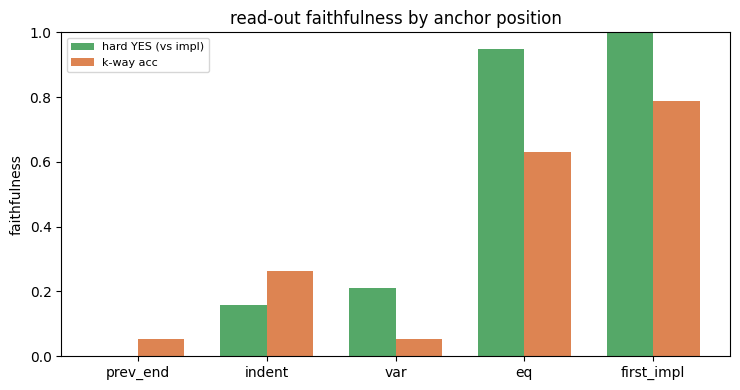

In [ ]:
# ── per-anchor summary + bar plot (hard-eval + k-way; soft dropped) ──
plt.rcdefaults()

agg = (eval_df.groupby("anchor")
       .agg(n=("hard_yes", "size"), hard_yes=("hard_yes", "mean"), kway_ok=("kway_ok", "mean"))
       .reindex([a for a in ANCHOR_ORDER if a in eval_df.anchor.unique()]))
st = Table(title=f"faithfulness by anchor position (N={eval_df.spec.nunique()} examples, config={GOALSCOPE_CONFIG['strategy']} α={GOALSCOPE_CONFIG['alpha']})")
for c in ["anchor", "n", "hard YES-rate", "k-way acc"]:
    st.add_column(c, justify=("left" if c == "anchor" else "right"))
for aname, r in agg.iterrows():
    st.add_row(aname, str(int(r.n)), f"{r.hard_yes:.2f}", f"{r.kway_ok:.2f}")
rich_print(st)

fig, ax = plt.subplots(figsize=(7.5, 4))
xs = np.arange(len(agg)); w = 0.36
ax.bar(xs - w/2, agg.hard_yes, w, label="hard YES (vs impl)", color="#55a868")
ax.bar(xs + w/2, agg.kway_ok, w, label="k-way acc", color="#dd8452")
ax.set_xticks(xs); ax.set_xticklabels(agg.index)
ax.set_ylim(0, 1); ax.set_ylabel("faithfulness"); ax.set_title("read-out faithfulness by anchor position")
ax.legend(fontsize=8); plt.tight_layout()
FIGDIR = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "goal_eval", MODEL_NAME.split("/")[-1])
os.makedirs(FIGDIR, exist_ok=True)
FIG = os.path.join(FIGDIR, "faithfulness_by_anchor.png")
plt.savefig(FIG, dpi=110, bbox_inches="tight"); print("saved", FIG); plt.show()

In [ ]:
res = all_recs[5]
res

{'spec': 'eval_int_00',
 'cond': 1,
 'var': 'b',
 'anchor': 'var',
 'pos': 277,
 'readout': "\n\nI haven't checked all conditions yet: \na = False\nb = False\nc = False\nd = False\ne = False\nf = False\ng = False\nh = False\ni = False\nj = False\nk = False\nl = False\nm = False\nr =",
 'impl_span': 'b = n % 2 == 0',
 'condition': 'n is even',
 'hard': 'NO',
 'hard_prompt': "Code: b = n % 2 == 0\nDescription: I haven't checked all conditions yet: \na = False\nb = False\nc = False\nd = False\ne = False\nf = False\ng = False\nh = False\ni = False\nj = False\nk = False\nl = False\nm = False\nr =\nAnswer:",
 'hard_response': 'The description shows variable initialization code, with no content relevant to checking if n is even (n % 2 == 0).\n\n<verdict>NO</verdict>',
 'kway_pred': 2,
 'kway_true': 1,
 'kway_prompt': "Conditions:\n0. n has at least 3 digits\n1. n is even\n2. n is smaller than the number obtained by reversing its digits\n3. the sum of n's digits is divisible by 5\n\nDescriptio

In [ ]:
res = [r for r in all_recs if r['anchor']=='eq' and r['kway_true']!=r['kway_pred']][0]
res

{'spec': 'eval_int_00',
 'cond': 0,
 'var': 'a',
 'anchor': 'eq',
 'pos': 267,
 'readout': '\n\nlen(str(len(str("123")) >= 0 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= ',
 'impl_span': 'a = len(str(n)) >= 3',
 'condition': 'n has at least 3 digits',
 'hard': 'YES',
 'hard_prompt': 'Code: a = len(str(n)) >= 3\nDescription: len(str(len(str("123")) >= 0 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >=\nAnswer:',
 'hard_response': 'The description mentions `len(str(...))` and a comparison with a numeric threshold, which is relevant to what the code does (computing `len(str(n)) >= 3`).\n\n<verdict>YES</verdict>',
 'kway_pred': None,
 'kway_true': 0,
 'kway_prompt': 'Conditions:\n0. n has at least 3 digits\n1. n is even\n2. n is smaller than the number obtained by reversing its digits\n3. the sum of n\'s digits is divisible by 5\n\nDescription: len(str(len(str("123")) >= 0 >=

In [ ]:
rich_print(res["kway_prompt"])

Conditions:
0. n has at least 3 digits
1. n is even
2. n is smaller than the number obtained by reversing its digits
3. the sum of n's digits is divisible by 5

Description: len(str(len(str("123")) >= 0 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 >= 99 
>= 99 >= 99 >= 99 >= 99 >= 99 >=
Which condition number does the description best match? Output only the integer, or -1 if none.

In [ ]:
ask_claude(
    prompt=res["kway_prompt"], system_prompt=_KWAY_SYS, max_tokens=KWAY_MAX_TOKENS,
)


'I need to evaluate the Python expression to find what it produces.\n\nLet me parse: `len(str(len(str("123")) >= 0 >= 99 >= 99 >= ... >= 99))`\n\nFirst, `str("123")` = `"123"`\n`len("123")` = `3`\n\nNow evaluate the chained comparison: `3 >= 0 >= 99 >= 99 >= ... >= 99`\n\nIn Python, chained comparisons are evaluated left to right. `3 >= 0` is True, but `0 >= 99` is False. So the entire chained comparison is `False`.\n\n`str(False)` = `"False"`\n`len("False")` = `5`\n\nSo the description evaluates to `5`.\n\nNow which condition does `5` match?\n\nCondition 3: "the sum of n\'s digits is divisible by 5"\n\n5 is divisible by 5, so this matches condition 3.\n\n3'

## 9. Parsing saved runs — `scripts.evaluation.faithfulness_io`

The consolidated eval lives in `scripts/evaluation/run_goalscope_faithfulness.py` (this notebook is the
sketch). Run it from a shell, e.g.

```bash
conda run -n goals python scripts/evaluation/run_goalscope_faithfulness.py \
    --heads goal --strategy additive --alpha 0.2 --steer_layer_range 35 46 \
    --n_steer_tokens all --max_new_tokens 64
```

It saves everything (config + selected heads, per-anchor records **with the raw oracle prompts and
responses**, per-anchor summary, per-sample generations + labels) under
`results/evaluation/goalscope/faithfulness/<strategy>/<alpha>/<leaf>/`. Parse it with `faithfulness_io`:

In [ ]:
from scripts.evaluation import faithfulness_io as fio

RES = env_utils.DEFAULT_RESULTS_DIR
runs = fio.list_runs(RES)
print(f"{len(runs)} saved run(s):")
for d in runs:
    print("  ", d.relative_to(fio.faithfulness_root(RES)))

if runs:
    run = fio.load_run(runs[-1])                          # dict(config, records, summary, samples, dir)
    print("\nconfig:", {k: run["config"][k] for k in
          ("heads_name", "strategy", "alpha", "steer_layer_range", "n_steer_tokens", "max_new_tokens", "n_heads")})

    # per-anchor faithfulness for this run
    rich_print(fio.summary_df(runs[-1]).to_string(index=False))

    # full records incl. raw oracle prompt+response — for polishing the system prompts
    recs = run["records"]
    print(f"\n{len(recs)} records; columns: {list(recs.columns)}")
    for _, r in recs[recs.hard != "YES"].head(3).iterrows():
        rich_print(f"[bold]{r['spec']} · {r['anchor']}[/bold]  hard={r['hard']}  kway={r['kway_pred']}/{r['kway_true']}")
        rich_print(f"   read-out : {escape(str(r['readout'])[:120])}")
        rich_print(f"   impl_span: {escape(str(r['impl_span']))}")
        rich_print(f"   hard resp: {escape(str(r['hard_response']))}")

# sweep every run's per-anchor summary (grid over design choices: heads/alpha/strategy/...)
fio.grid_df(RES)

2 saved run(s):
   additive/0.2/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123
   replace/1/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123

config: {'heads_name': 'goal', 'strategy': 'replace', 'alpha': 1.0, 'steer_layer_range': [35, 46], 'n_steer_tokens': 'all', 'max_new_tokens': 64, 'n_heads': 122}


anchor strategy  alpha heads_name  n_heads steer_layer_range n_steer_tokens  max_new_tokens  seed    n  
hard_yes  kway_ok
  prev_end  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.274877 0.222660
    indent  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.617734 0.530049
       var  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.515271 0.486700
        eq  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.966502 0.887685
first_impl  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.943842 0.878818
   OVERALL  replace    1.0       goal      122          [35, 46]            all              64   123 5075  
0.663645 0.601182


5075 records; columns: ['spec', 'cond', 'var', 'anchor', 'pos', 'readout', 'impl_span', 'condition', 'true_pred_id', 'hard', 'hard_prompt', 'hard_response', 'kway_pred', 'kway_true', 'kway_prompt', 'kway_response']


eval_int_00 · var  hard=NO_INFO  kway=nan/0

read-out : Checking if a variable is true.

impl_span: a = round(n ** (1/3)) ** 3 == n

... (6 outputs left out)

read-out : Checking if a variable meets a condition.

impl_span: b = n >= 10

hard resp: NO_INFO

,anchor,strategy,alpha,heads_name,n_heads,steer_layer_range,n_steer_tokens,max_new_tokens,seed,n,hard_yes,kway_ok
0,prev_end,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.515271,0.262069
1,indent,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.813793,0.564532
2,var,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.749754,0.579310
3,eq,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.993103,0.927094
4,first_impl,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.993103,0.901478
5,OVERALL,additive,0.2,goal,122,"[35, 46]",all,64,123,5075,0.813005,0.646897
6,prev_end,replace,1.0,goal,122,"[35, 46]",all,64,123,1015,0.274877,0.222660
7,indent,replace,1.0,goal,122,"[35, 46]",all,64,123,1015,0.617734,0.530049
8,var,replace,1.0,goal,122,"[35, 46]",all,64,123,1015,0.515271,0.486700
9,eq,replace,1.0,goal,122,"[35, 46]",all,64,123,1015,0.966502,0.887685


plotting: additive/0.2/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123


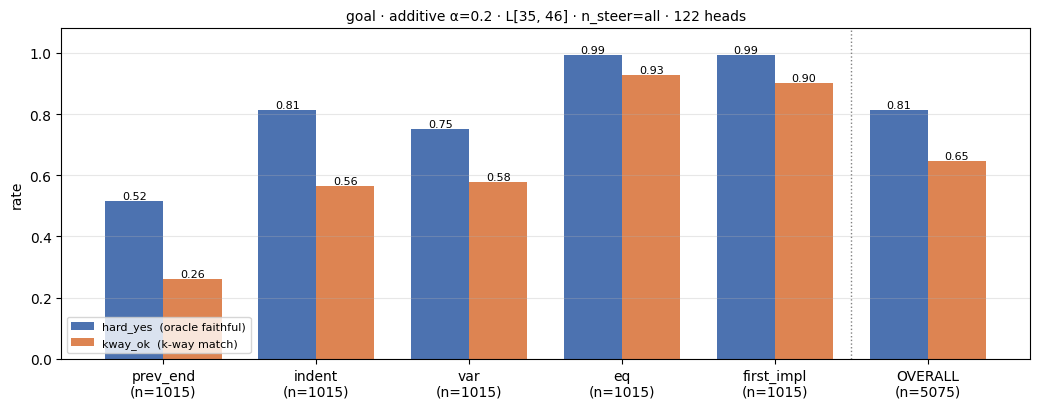

In [ ]:
# ── plot one saved run: per-anchor faithfulness (hard_yes) + k-way accuracy (kway_ok) ──
import numpy as np
import matplotlib.pyplot as plt
from scripts.evaluation import faithfulness_io as fio

RES = env_utils.DEFAULT_RESULTS_DIR
ANCHOR_ORDER = ["prev_end", "indent", "var", "eq", "first_impl"]


def plot_run(run_name, res=RES):
    """run_name = path under the faithfulness root (e.g. 'additive/0.2/<leaf>', as printed by
    fio.list_runs). Grouped bars of hard_yes + kway_ok per anchor, with OVERALL split off."""
    run_dir = fio.faithfulness_root(res) / run_name
    cfg, summ = fio.load_config(run_dir), fio.load_summary(run_dir)

    anchors = [a for a in ANCHOR_ORDER if a in summ["by_anchor"]]
    hard = [summ["by_anchor"][a]["hard_yes"] for a in anchors]
    kway = [summ["by_anchor"][a]["kway_ok"] for a in anchors]
    ns   = [summ["by_anchor"][a]["n"] for a in anchors]
    labels = anchors + ["OVERALL"]                       # OVERALL appended on the right
    hard  += [summ["overall"]["hard_yes"]]
    kway  += [summ["overall"]["kway_ok"]]
    ns    += [summ.get("n_records")]

    x = np.arange(len(labels)); w = 0.38
    fig, ax = plt.subplots(figsize=(1.5 * len(labels) + 1.5, 4.2))
    b1 = ax.bar(x - w / 2, hard, w, label="hard_yes  (oracle faithful)", color="#4c72b0")
    b2 = ax.bar(x + w / 2, kway, w, label="kway_ok  (k-way match)",       color="#dd8452")
    for bars in (b1, b2):
        for r in bars:
            ax.annotate(f"{r.get_height():.2f}", (r.get_x() + r.get_width() / 2, r.get_height()),
                        ha="center", va="bottom", fontsize=8)
    ax.axvline(len(anchors) - 0.5, color="grey", ls=":", lw=1)     # divider before OVERALL
    ax.set_xticks(x); ax.set_xticklabels([f"{a}\n(n={n})" for a, n in zip(labels, ns)])
    ax.set_ylim(0, 1.08); ax.set_ylabel("rate"); ax.grid(axis="y", alpha=0.3)
    title = (f"{cfg.get('heads_name')} · {cfg.get('strategy')} α={cfg.get('alpha')} · "
             f"L{cfg.get('steer_layer_range')} · n_steer={cfg.get('n_steer_tokens')} · "
             f"{cfg.get('n_heads')} heads")
    ax.set_title(title, fontsize=10); ax.legend(loc="lower left", fontsize=8)
    fig.tight_layout(); plt.show()
    return run_dir


# example: plot the most recent run (pass any run_name from fio.list_runs above)
_runs = fio.list_runs(RES)
if _runs:
    _name = str(_runs[0].relative_to(fio.faithfulness_root(RES)))
    print("plotting:", _name)
    plot_run(_name)
else:
    print("no saved faithfulness runs found under", fio.faithfulness_root(RES))


In [ ]:
runs

[PosixPath('/disk/u/arnab/Codes/Projects/goals/results/evaluation/goalscope/faithfulness/additive/0.2/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123'),
 PosixPath('/disk/u/arnab/Codes/Projects/goals/results/evaluation/goalscope/faithfulness/replace/1/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123')]